# Patient risk model: training and comparing with NEWS2

**Goal:** for every hour of an ICU stay, estimate the risk that **sepsis will be recognised within the next
6 hours**, using only what MedTwin measures (prepared in `03_risk_data.ipynb`).

**Three models**, from simple to powerful: **Logistic Regression**, **Random Forest** and **XGBoost**.

**A fair comparison:**
* Only **1.1%** of hours are warning hours, so the models weight them more, and plain accuracy is never used.
* Each model's **alarm level** is set (on validation patients) so that it raises **as many alarms as NEWS2 ≥ 5**.
  Then the question is simply: which one catches more real warning hours?
* Training uses the "train" patients of both hospital systems; 10% of them are held back as **validation**
  patients for choices; everything reported comes from the untouched **test** patients.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA, MODELS, RESULTS = Path("../data/physionet2019"), Path("../models"), Path("../results")
df = pd.read_parquet(DATA / "risk_features.parquet")
FEATURES = pd.read_csv(DATA / "risk_feature_names.csv", header=None)[0].tolist()

# Hold back 10% of the training patients for validation choices (alarm levels, when to stop training).
train_patients = df.loc[df.split == "train", "patient"].unique()
validation_patients = set(np.random.default_rng(7).choice(train_patients, size=len(train_patients) // 10, replace=False))
df.loc[df.patient.isin(validation_patients), "split"] = "validation"

parts = {name: df[df.split == name] for name in ("train", "validation", "test")}
for name, part in parts.items():
    print(f"{name:<10} {part.patient.nunique():>6,} patients  {len(part):>9,} hours  {100 * part.target.mean():.2f}% warning hours")
X = {name: part[FEATURES] for name, part in parts.items()}
y = {name: part["target"].values for name, part in parts.items()}

train      29,071 patients  1,110,905 hours  1.14% warning hours
validation  3,230 patients    121,153 hours  1.18% warning hours
test        8,035 patients    309,787 hours  1.11% warning hours


## Training

* **Logistic Regression:** gaps the model can't handle are filled with typical (median) values, everything is put
  on the same scale, and warning hours are weighted to count as much as all normal hours together.
* **Random Forest:** 300 trees. To keep training time reasonable on 1.1 million hours, it learns from **all**
  warning hours plus a random **10%** of normal hours (the rest of the normal hours add little).
* **XGBoost:** up to 1,000 rounds, **stopping early** once the validation patients stop improving (so it
  doesn't memorise the training patients), with warning hours weighted up.

In [2]:
models = {}

models["Logistic Regression"] = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
).fit(X["train"], y["train"])

rng = np.random.default_rng(0)
keep = (y["train"] == 1) | (rng.random(len(y["train"])) < 0.10)
models["Random Forest"] = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=50, max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1, random_state=0
).fit(X["train"][keep], y["train"][keep])

weight = (y["train"] == 0).sum() / (y["train"] == 1).sum()
models["XGBoost"] = xgb.XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=20, scale_pos_weight=weight, eval_metric="aucpr", early_stopping_rounds=50,
    tree_method="hist", n_jobs=-1, random_state=0,
).fit(X["train"], y["train"], eval_set=[(X["validation"], y["validation"])], verbose=False)
print("XGBoost stopped after", models["XGBoost"].best_iteration + 1, "rounds")

XGBoost stopped after 77 rounds


## Results on the test patients

The alarm level for each model is chosen on the **validation** patients so that it alarms in the same share of
hours as NEWS2 ≥ 5 does. On the test patients we then compare:

* **AUROC / AUPRC:** overall ranking quality (higher is better; AUPRC is the one to watch when the target is rare).
* **Catches:** the share of warning hours that raise an alarm (*sensitivity*, or *recall*).
* **Alarms that are right:** the share of alarms that really were in a warning window (*precision*).
* **Patients caught:** the share of sepsis patients who got **at least one** alarm in their 6-hour window, which
  is what matters at the bedside.

In [3]:
def scores(name, part):
    if name == "NEWS2":
        return parts[part]["news2"].values.astype(float)
    return models[name].predict_proba(X[part])[:, 1]


alarm_share = (parts["validation"]["news2"] >= 5).mean()  # how often NEWS2 >= 5 alarms
thresholds = {"NEWS2": 5}
for name in models:
    thresholds[name] = float(np.quantile(scores(name, "validation"), 1 - alarm_share))


def patients_caught(part, alarms):
    window = part.assign(alarm=alarms)[part.target == 1]
    return window.groupby("patient")["alarm"].max().mean()


test = parts["test"]
rows = []
for name in ["NEWS2", *models]:
    score = scores(name, "test")
    alarms = score >= thresholds[name]
    rows.append({
        "model": name,
        "AUROC": roc_auc_score(y["test"], score),
        "AUPRC": average_precision_score(y["test"], score),
        "hours alarmed %": 100 * alarms.mean(),
        "catches %": 100 * alarms[y["test"] == 1].mean(),
        "alarms that are right %": 100 * y["test"][alarms].mean(),
        "patients caught %": 100 * patients_caught(test, alarms),
    })
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison.to_csv(RESULTS / "risk_model_comparison.csv")
print(f"Alarm level matched to NEWS2 >= 5, which alarms in {100 * alarm_share:.1f}% of hours")
comparison.round({"AUROC": 3, "AUPRC": 3, "hours alarmed %": 1, "catches %": 1, "alarms that are right %": 2, "patients caught %": 1})

Alarm level matched to NEWS2 >= 5, which alarms in 24.4% of hours


,AUROC,AUPRC,hours alarmed %,catches %,alarms that are right %,patients caught %
model,,,,,,
NEWS2,0.663,0.019,24.1,45.9,2.11,71.9
Logistic Regression,0.725,0.041,25.0,58.6,2.59,69.6
Random Forest,0.798,0.062,25.6,67.9,2.94,81.3
XGBoost,0.795,0.067,25.5,67.3,2.93,81.3


Best model: XGBoost
  catches 67% of warning hours vs 46% for NEWS2, with the same number of alarms
  alarms that are right: 2.9% vs 2.1%
  sepsis patients caught in their warning window: 81% vs 72%


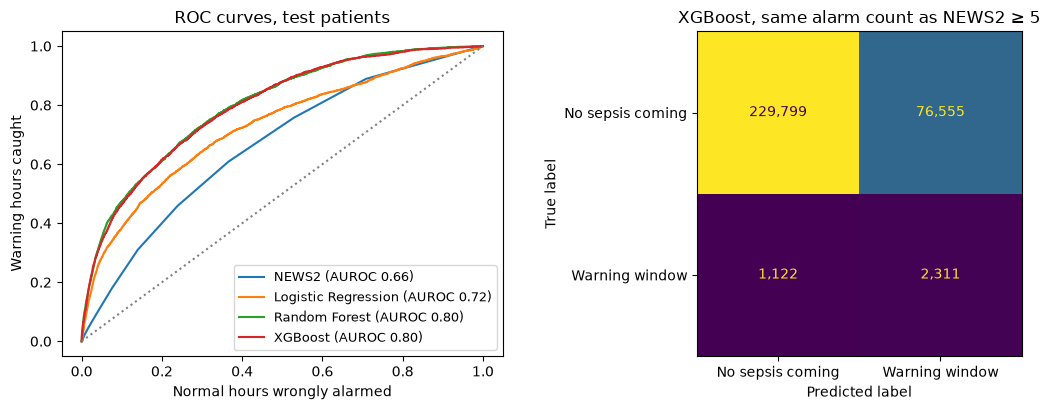

In [4]:
best = comparison.drop(index="NEWS2")["AUPRC"].idxmax()
news2, top = comparison.loc["NEWS2"], comparison.loc[best]
print(f"Best model: {best}")
print(f"  catches {top['catches %']:.0f}% of warning hours vs {news2['catches %']:.0f}% for NEWS2, with the same number of alarms")
print(f"  alarms that are right: {top['alarms that are right %']:.1f}% vs {news2['alarms that are right %']:.1f}%")
print(f"  sepsis patients caught in their warning window: {top['patients caught %']:.0f}% vs {news2['patients caught %']:.0f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name in ["NEWS2", *models]:
    false_alarm, caught, _ = roc_curve(y["test"], scores(name, "test"))
    axes[0].plot(false_alarm, caught, label=f"{name} (AUROC {comparison.loc[name, 'AUROC']:.2f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls=":")
axes[0].set_xlabel("Normal hours wrongly alarmed")
axes[0].set_ylabel("Warning hours caught")
axes[0].set_title("ROC curves, test patients")
axes[0].legend(loc="lower right", fontsize=9)

matrix = confusion_matrix(y["test"], scores(best, "test") >= thresholds[best])
ConfusionMatrixDisplay(matrix, display_labels=["No sepsis coming", "Warning window"]).plot(ax=axes[1], colorbar=False, values_format=",")
axes[1].set_title(f"{best}, same alarm count as NEWS2 ≥ 5")
plt.tight_layout()
plt.savefig(RESULTS / "risk_model_comparison.png", dpi=150)
plt.show()

## Risk levels for MedTwin

MedTwin shows each patient as **low**, **medium** or **high** risk (the green, amber and red beds on the map).
The levels are set like the NEWS2 triggers, using the validation patients:

* **High:** the model's top alarms, as often as NEWS2 ≥ 7 (emergency response).
* **Medium:** as often as NEWS2 ≥ 5 (urgent review).
* **Low:** everything else.

In [5]:
high_share = (parts["validation"]["news2"] >= 7).mean()
validation_scores = scores(best, "validation")
levels = {
    "medium": float(np.quantile(validation_scores, 1 - alarm_share)),
    "high": float(np.quantile(validation_scores, 1 - high_share)),
}
test_scores = scores(best, "test")
level = np.where(test_scores >= levels["high"], "HIGH", np.where(test_scores >= levels["medium"], "MEDIUM", "LOW"))
check = pd.DataFrame({"level": level, "warning": y["test"]}).groupby("level")["warning"].agg(["size", "mean"])
check.columns = ["hours", "share that are warning hours"]
check["share of all hours %"] = (100 * check["hours"] / check["hours"].sum()).round(1)
check["share that are warning hours"] = (100 * check["share that are warning hours"]).round(2).astype(str) + "%"
print("Risk levels on the test patients (higher level = more likely a warning hour):")
check.loc[["LOW", "MEDIUM", "HIGH"]]

Risk levels on the test patients (higher level = more likely a warning hour):


,hours,share that are warning hours,share of all hours %
level,,,
LOW,230921,0.49%,74.5
MEDIUM,51587,1.59%,16.7
HIGH,27279,5.47%,8.8


In [6]:
bundle = {
    "model": models[best],
    "name": best,
    "features": FEATURES,
    "levels": levels,
    "target": "sepsis recognised within the next 6 hours (PhysioNet 2019 definition)",
    "trained_on": "PhysioNet 2019, training patients of hospital systems A and B",
    "comparison": comparison.reset_index().to_dict(orient="records"),
}
joblib.dump(bundle, MODELS / "risk_model.joblib", compress=3)
print("Saved", MODELS / "risk_model.joblib", f"({(MODELS / 'risk_model.joblib').stat().st_size / 1e6:.1f} MB)")

Saved ..\models\risk_model.joblib (0.2 MB)


## Notes for the report

* **Fair comparison:** all models are compared with NEWS2 at the **same alarm burden**, chosen on validation
  patients; the test patients are only used once, for the final numbers.
* **Imbalance:** warning hours are weighted up (or normal hours sampled down for the Random Forest), and the
  metrics are AUROC, AUPRC, sensitivity and precision, never plain accuracy.
* **Vital signs only:** published sepsis models that also use laboratory results score higher; MedTwin's model is
  restricted to the vital signs its digital twin measures.
* **Next (Day 26):** explain individual predictions with **SHAP**, and test how well the model works on a hospital
  system it has never seen.